In [41]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper

# Figure 2

In [42]:
adata_hao = anndata.read_h5ad('../data/hao_adata.h5ad')

## Figure 2A

In [23]:
# Load Bulks
bulks_chen = pd.read_csv("../data/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/bulks_hoek_tpm.csv", index_col=0)



In [ ]:
estimations_fino, signature_results_fino = rp.rectangle(adata_hao, bulks_fino.T)


In [32]:
estimations_fino.to_csv("../output/hao_estimations_fino.csv")

In [33]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T

<Axes: title={'center': 'Finotello'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

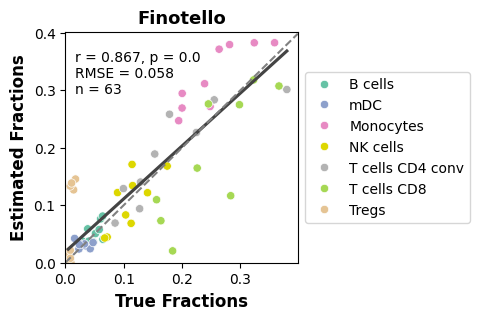

In [37]:
gld_m, finotello_m = helper.match_dfs(finotello_gld, estimations_fino.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
finotello_m = finotello_m.sort_index(key=lambda x: x.str.lower())
evaluation_fintotello_rectangle = helper.create_evaluation_df(gld_m, finotello_m)
rsme_finotello_rectangle, r_finotello_rectangle, p_finotello_rectangle = helper.evaulate_total_df(
    evaluation_fintotello_rectangle)
rsmes_f_rectangle, ps_f_rectangle, rs_f_rectangle = helper.evaluate_by_cell_type(gld_m, finotello_m)
helper.create_scatter_plot_total(evaluation_fintotello_rectangle, rsme_finotello_rectangle, p_finotello_rectangle,
                                 r_finotello_rectangle,
                                 'Finotello', save_path='../figures/fig2a_fino.pdf', size=(3, 3))